# Лабораторная работа №2: Семантическая сегментация

**Студент:** Максимова Алина

**Группа:** 6233-010402D

**Модель:** UNet

**Датасет:** Pascal VOC 2012

## Цель
Освоить методы семантической сегментации изображений на примере архитектур UNet и DeepLabv3+, изучить метрики качества (IoU, Dice).

## Теория
- Классификация vs. детекция vs. сегментация.
- Архитектура UNet и её особенности.
- DeepLabv3+ и dilated convolutions.
- Метрики: IoU, Dice.

## Задания
1. Выберите модель (UNet или DeepLabv3+).
2. Возьмите датасет (Carvana, Pascal VOC или Cityscapes subset).
3. Подготовьте данные и обучите модель сегментации.
4. Оцените качество с использованием IoU и Dice.
5. Визуализируйте результаты (картинки с наложением предсказанных масок).
6. Проведите эксперимент с разными размерами входного изображения или с аугментациями.

## Вопросы
1. Почему accuracy плохо отражает качество сегментации?
2. Чем UNet отличается от "обычной" CNN?

## Требуемое содержание файла проекта
- Иллюстрации входных изображений и масок.
- Примеры предсказаний модели.
- Сравнительный анализ экспериментов.
- Ответы на контрольные вопросы.

## 1. Классификация, детекция и сегментация

- **Классификация** — определяет класс объекта для всего изображения (один или несколько тегов), без указания местоположения.
- **Детекция** — находит объекты на изображении и определяет их класс, выделяя каждый объект ограничивающей рамкой.
- **Сегментация** — размечает изображение на уровне пикселей: semantic — класс для каждого пикселя, instance — отдельные объекты каждого класса.

## 2. Архетиктура UNet и ее особенности

UNet — это сверточная нейронная сеть для задач семантической сегментации.

Архитектура имеет U-образную форму и состоит из двух основных частей:

Кодировщик — последовательно извлекает признаки высокого уровня и уменьшает пространственное разрешение изображения с помощью сверток и пулинга.

Декодировщик — восстанавливает пространственное разрешение с помощью операций upsampling.

Особенность: Skip Connections напрямую передают карты признаков с соответствующих уровней кодировщика в декодировщик. Это позволяет объединить низкоуровневую пространственную информацию (точные границы, края) с высокоуровневой семантической информацией (контекст).


## 3. DeepLabv3+ и dilated convolutions

DeepLabv3+ — архитектура сегментации, направленная на решение проблемы захвата контекста на разных масштабах.

Ключевые компоненты:

Dilated Convolutions — это свертки, в которых ядро «расширяется» путем вставки промежутков (нулей) между его элементами.

ASPP — модуль, который применяет несколько параллельных дилатационных сверток с разными коэффициентами d для захвата многомасштабного контекста.

DeepLabv3+ использует кодировщик с модулем ASPP для извлечения многомасштабных признаков, а затем простой декодировщик для восстановления деталей объектов, комбинируя высокоуровневые признаки с низкоуровневыми.


## 4. Метрики: IoU и Dice
Для оценки качества сегментации используются метрики, основанные на пересечении предсказанной маски (A) и истинной маски (B).

IoU — отношение площади пересечения масок к площади их объединения.

Формула:
$$
IoU = \frac{|A ∩ B|}{|A ∪ B|}
$$

Варьируется от 0 (нет пересечения) до 1 (полное совпадение).

Dice — удвоенная площадь пересечения, деленная на сумму площадей масок. Эта метрика особенно чувствительна к маленьким объектам.

Формула:

$$
Dice = 2 * \frac{|A ∩ B|} {(|A| + |B|)}
$$

В диапазоне от 0 до 1.

## Установка необходимых модулей

In [ ]:
!pip install -q segmentation-models-pytorch albumentations

## Импорт библиотек

In [ ]:
import gc
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset, ConcatDataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm import tqdm
from torchvision import datasets

## Проверка устройства (cuda)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


## Конфигурация

In [ ]:
DATA_DIR         = './data'
ENCODER          = 'resnet34'
ENCODER_WEIGHTS  = 'imagenet'
NUM_CLASSES      = 21
IGNORE_INDEX     = 255
EPOCHS           = 20
BASE_LR          = 3e-4
WEIGHT_DECAY     = 1e-4
SEED             = 42
NUM_WORKERS      = 2

torch.manual_seed(SEED)
np.random.seed(SEED)

## Подготовка данных и DataLoader’ы для семантической сегментации

In [ ]:
class VOCDatasetAlbumentations(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, mask = self.dataset[idx]
        image = np.array(image)
        mask = np.array(mask)
        if self.transform is not None:
            aug = self.transform(image=image, mask=mask)
            image, mask = aug['image'], aug['mask']
        return image, mask


def build_transforms(img_size, use_augmentation):
    resize = A.Resize(img_size, img_size)
    norm = A.Normalize(mean=(0.485, 0.456, 0.406),
                       std=(0.229, 0.224, 0.225))
    aug_ops = []
    if use_augmentation:
        aug_ops = [
            A.HorizontalFlip(p=0.5),
            A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
        ]
    train_tf = A.Compose([resize, *aug_ops, norm, ToTensorV2()])
    val_tf   = A.Compose([resize, norm, ToTensorV2()])
    return train_tf, val_tf


def build_full_dataset(data_dir=DATA_DIR):
    ds_train = datasets.VOCSegmentation(root=data_dir, year='2012',
                                        image_set='train', download=True)
    ds_val   = datasets.VOCSegmentation(root=data_dir, year='2012',
                                        image_set='val',   download=True)
    return ConcatDataset([ds_train, ds_val])


def get_dataloaders(full_ds, img_size, use_augmentation=False,
                    batch_size=None, seed=SEED, num_workers=NUM_WORKERS):
    train_tf, val_tf = build_transforms(img_size, use_augmentation)

    total    = len(full_ds)
    n_train  = int(0.8 * total)
    n_val    = int(0.1 * total)
    n_test   = total - n_train - n_val

    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(total, generator=g).tolist()
    train_idx = perm[:n_train]
    val_idx   = perm[n_train:n_train + n_val]
    test_idx  = perm[n_train + n_val:]

    train_ds = Subset(VOCDatasetAlbumentations(full_ds, train_tf), train_idx)
    val_ds   = Subset(VOCDatasetAlbumentations(full_ds, val_tf),   val_idx)
    test_ds  = Subset(VOCDatasetAlbumentations(full_ds, val_tf),   test_idx)

    bs = batch_size or (16 if img_size <= 128 else 8)
    train_loader = DataLoader(train_ds, batch_size=bs, shuffle=True,
                              num_workers=num_workers, pin_memory=True,
                              drop_last=True)
    val_loader   = DataLoader(val_ds, batch_size=bs, shuffle=False,
                              num_workers=num_workers, pin_memory=True)
    test_loader  = DataLoader(test_ds, batch_size=bs, shuffle=False,
                              num_workers=num_workers, pin_memory=True)
    return train_loader, val_loader, test_loader

## Функция потерь

In [ ]:
class ComboLoss(nn.Module):
    # CrossEntropy + Dice
    def __init__(self, weight_ce=0.5, weight_dice=0.5, ignore_index=IGNORE_INDEX):
        super().__init__()
        self.w_ce   = weight_ce
        self.w_dice = weight_dice
        self.ce   = nn.CrossEntropyLoss(ignore_index=ignore_index)
        self.dice = smp.losses.DiceLoss(mode='multiclass',
                                        ignore_index=ignore_index,
                                        from_logits=True)

    def forward(self, preds, targets):
        return self.w_ce * self.ce(preds, targets) + self.w_dice * self.dice(preds, targets)

## Метрики качества

In [ ]:
class SegmentationMetrics:
    def __init__(self, num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX):
        self.num_classes  = num_classes
        self.ignore_index = ignore_index
        self.cm = np.zeros((num_classes, num_classes), dtype=np.int64)

    def reset(self):
        self.cm.fill(0)

    def update(self, logits, targets):
        preds = torch.argmax(logits, dim=1)
        valid = targets != self.ignore_index
        p = preds[valid].detach().cpu().numpy().astype(np.int64)
        t = targets[valid].detach().cpu().numpy().astype(np.int64)
        idx = t * self.num_classes + p
        self.cm += np.bincount(idx, minlength=self.num_classes ** 2) \
                     .reshape(self.num_classes, self.num_classes)

    def compute(self, include_background=True):
        cm = self.cm if include_background else self.cm[1:, 1:]
        tp = np.diag(cm)
        fp = cm.sum(axis=0) - tp
        fn = cm.sum(axis=1) - tp
        denom = tp + fp + fn
        valid = denom > 0
        iou  = tp[valid] / denom[valid]
        dice = 2 * tp[valid] / (2 * tp[valid] + fp[valid] + fn[valid])
        return float(iou.mean()), float(dice.mean())

## Инициализация модели

In [ ]:
def build_model(encoder=ENCODER, weights=ENCODER_WEIGHTS):
    return smp.Unet(
        encoder_name=encoder,
        encoder_weights=weights,
        in_channels=3,
        classes=NUM_CLASSES,
    ).to(device)

## Обучение и оценка модели

In [ ]:
def evaluate(model, loader, loss_fn=None):
    model.eval()
    metrics = SegmentationMetrics()
    total_loss, n_batches = 0.0, 0
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks  = masks.long().to(device, non_blocking=True)
            if masks.dim() == 4:
                masks = masks.squeeze(1)
            outputs = model(images)
            if loss_fn is not None:
                total_loss += loss_fn(outputs, masks).item()
            metrics.update(outputs, masks)
            n_batches += 1
    iou, dice = metrics.compute(include_background=True)
    avg_loss = total_loss / max(n_batches, 1) if loss_fn is not None else None
    return iou, dice, avg_loss


def train_one_experiment(model, train_loader, val_loader, test_loader,
                         epochs=EPOCHS, lr=BASE_LR, wd=WEIGHT_DECAY):
    loss_fn   = ComboLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=1e-6)

    history = {'train_loss': [], 'val_loss': [], 'val_iou': [], 'val_dice': []}
    best_iou, best_state = -1.0, None

    for epoch in range(epochs):
        # train
        model.train()
        running = 0.0
        pbar = tqdm(train_loader, leave=False,
                    desc=f"Epoch {epoch+1}/{epochs} [train]")
        for images, masks in pbar:
            images = images.to(device, non_blocking=True)
            masks  = masks.long().to(device, non_blocking=True)
            if masks.dim() == 4:
                masks = masks.squeeze(1)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = loss_fn(outputs, masks)
            loss.backward()
            optimizer.step()

            running += loss.item()
            pbar.set_postfix(loss=f"{loss.item():.4f}")

        # val
        val_iou, val_dice, val_loss = evaluate(model, val_loader, loss_fn)
        avg_train = running / max(len(train_loader), 1)

        history['train_loss'].append(avg_train)
        history['val_loss'].append(val_loss)
        history['val_iou'].append(val_iou)
        history['val_dice'].append(val_dice)

        if val_iou > best_iou:
            best_iou = val_iou
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}

        scheduler.step()
        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"Train {avg_train:.4f} | Val {val_loss:.4f} | "
              f"IoU {val_iou:.4f} | Dice {val_dice:.4f} | best IoU {best_iou:.4f}")

    # test on best weights
    if best_state is not None:
        model.load_state_dict(best_state)
    test_iou, test_dice, test_loss = evaluate(model, test_loader, loss_fn)

    final = {
        'best_val_iou': best_iou,
        'test_iou':     test_iou,
        'test_dice':    test_dice,
        'test_loss':    test_loss,
    }
    return history, final


def run_experiment(name, full_ds, img_size, use_augmentation):
    print(f"\n=== {name} (img_size={img_size}, aug={use_augmentation}) ===")
    train_loader, val_loader, test_loader = get_dataloaders(
        full_ds, img_size, use_augmentation)

    model = build_model()
    history, final = train_one_experiment(
        model, train_loader, val_loader, test_loader)

    model.eval()  # фиксируем eval-режим для визуализации
    return {
        'model':       model,
        'test_loader': test_loader,
        'history':     history,
        'final':       final,
    }

## Визуализация результатов

In [ ]:
@torch.no_grad()
def visualize_predictions(model, loader, save_path=None, n=4, title='',
                          show=True):
    # Image | GT | Prediction | Overlay для примеров
    model.eval()
    images_batch, masks_batch = next(iter(loader))
    images_batch = images_batch[:n].to(device)
    masks_batch  = masks_batch[:n]

    logits = model(images_batch)
    preds  = torch.argmax(logits, dim=1).cpu().numpy()

    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = axes[None, :]

    for i in range(n):
        img_np  = denormalize(images_batch[i])
        gt_np   = masks_batch[i].cpu().numpy()
        if gt_np.ndim == 3:
            gt_np = gt_np.squeeze(0)
        pred_np = preds[i]

        axes[i, 0].imshow(img_np);                        axes[i, 0].set_title('Image')
        axes[i, 1].imshow(colorize_mask(gt_np));          axes[i, 1].set_title('GT')
        axes[i, 2].imshow(colorize_mask(pred_np));        axes[i, 2].set_title('Prediction')
        axes[i, 3].imshow(overlay_mask(img_np, pred_np)); axes[i, 3].set_title('Overlay')
        for ax in axes[i]:
            ax.axis('off')

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved: {save_path}")

    if show:
        plt.show()

    plt.close(fig)

## Освобождение памяти

In [ ]:
def cleanup_experiments(experiments, delete_models_only=True):
    # Освобождает GPU-память, занятую моделями.
    for exp in experiments.values():
        if 'model' in exp:
            del exp['model']          # убираем последнюю ссылку на модель

    if not delete_models_only:
        experiments.clear()

    gc.collect()
    torch.cuda.empty_cache()
    print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1e6:.1f} MB")

## Функции подготовки изображений и масок к визуализации

In [ ]:
VOC_PALETTE = np.array([
    [0,   0,   0],   # background
    [128, 0,   0],   # aeroplane
    [0, 128,   0],   # bicycle
    [128, 128, 0],   # bird
    [0,   0, 128],   # boat
    [128, 0, 128],   # bottle
    [0, 128, 128],   # bus
    [128, 128, 128], # car
    [64,  0,   0],   # cat
    [192, 0,   0],   # chair
    [64, 128,   0],  # cow
    [192, 128, 0],   # dining table
    [64,  0, 128],   # dog
    [192, 0, 128],   # horse
    [64, 128, 128],  # motorbike
    [192, 128, 128], # person
    [0,  64,   0],   # potted plant
    [128, 64,   0],  # sheep
    [0, 192,   0],   # sofa
    [128, 192, 0],   # train
    [0,   0,  192],  # tv/monitor
], dtype=np.uint8)

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])


def denormalize(img_tensor):
    # [3,H,W] нормализованный тензор -> [H,W,3]
    img = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img = img * IMAGENET_STD + IMAGENET_MEAN
    return (np.clip(img, 0, 1) * 255).astype(np.uint8)


def colorize_mask(mask, palette=VOC_PALETTE, ignore_index=255):
    # [H,W] индексы классов -> [H,W,3]
    mask = mask.copy()
    mask[mask == ignore_index] = 0
    return palette[mask]


def overlay_mask(image_rgb, mask, palette=VOC_PALETTE, alpha=0.5):
    color = colorize_mask(mask, palette)
    overlay = image_rgb.copy()
    fg = mask != 0
    overlay[fg] = (alpha * color[fg] + (1 - alpha) * image_rgb[fg]).astype(np.uint8)
    return overlay

## Эксперименты

In [ ]:
full_ds = build_full_dataset()
print(f"Total dataset size: {len(full_ds)}")

experiments = {
    'base': run_experiment('Base 128x128',      full_ds, 128, False),
    'aug':  run_experiment('Augmented 128x128', full_ds, 128, True),
    'big':  run_experiment('Big 256x256',       full_ds, 256, False),
}

print("\n=== Final summary ===")
for name, exp in experiments.items():
    f = exp['final']
    print(f"{name:>4}: best val IoU={f['best_val_iou']:.4f} | "
          f"test IoU={f['test_iou']:.4f} | test Dice={f['test_dice']:.4f}")

Total dataset size: 2913

=== Base 128x128 (img_size=128, aug=False) ===


Epoch 01/30 | Train 1.1575 | Val 0.8029 | IoU 0.0884 | Dice 0.1218 | best IoU 0.0884


Epoch 02/30 | Train 0.7557 | Val 0.7206 | IoU 0.1032 | Dice 0.1408 | best IoU 0.1032


Epoch 03/30 | Train 0.6946 | Val 0.6777 | IoU 0.1153 | Dice 0.1604 | best IoU 0.1153


Epoch 04/30 | Train 0.6489 | Val 0.6722 | IoU 0.1191 | Dice 0.1655 | best IoU 0.1191


Epoch 05/30 | Train 0.6123 | Val 0.6456 | IoU 0.1870 | Dice 0.2619 | best IoU 0.1870


... (81 outputs left out)

Epoch 27/30 | Train 0.0679 | Val 0.3969 | IoU 0.4786 | Dice 0.6115 | best IoU 0.4993


Epoch 28/30 | Train 0.0669 | Val 0.3873 | IoU 0.4962 | Dice 0.6296 | best IoU 0.4993


Epoch 29/30 | Train 0.0653 | Val 0.3927 | IoU 0.4933 | Dice 0.6271 | best IoU 0.4993


Epoch 30/30 | Train 0.0659 | Val 0.4171 | IoU 0.4788 | Dice 0.6142 | best IoU 0.4993

=== Final summary ===
base: best val IoU=0.4050 | test IoU=0.3807 | test Dice=0.5175
 aug: best val IoU=0.4277 | test IoU=0.3974 | test Dice=0.5300
 big: best val IoU=0.4993 | test IoU=0.4467 | test Dice=0.5914


**Выводы:**

Базовая модель:


*   Быстрая сходимость: loss 1,16 -> 0,12
*   Разрыв train/val по лоссу к концу ~0,45
*   Лучший val IoU достигается только к 30-й эпохе (0,4050), test IoU 0,3807, Dice 0,5175.


Модель с аугментациями:



*   Сходимость медленнее, чем у базовой модели (loss 1,19 -> 0,22)
*   Разрыв train/val по лоссу ~0,25, что меньше чем у базовой модели и модели с увеличенным размером
*   Аug улучшает test относительно base: IoU 0,3974, Dice 0,5300.
*   Модель выглядит недотренированной (лучший val IoU — на последней эпохе).



Модель с увеличенным размером:




*   Сходимость: train loss 0,91 → 0,07 (самая низкая относительно других моделей)
*   Разрыв train/val по лоссу ~0,35
*   Переход 128→256 даёт +0.066 test IoU и +0.074 Dice относительно base.
*   Лучший результат: test IoU 0,4467, Dice 0,5914, best val IoU 0,4993.



**Замечание:**

Значения метрик (довольно низкие) обусловлены тем, что изображения взяты как 128х128 и 256х256, когда изначальные размеры, представленные в датасете около 500х350, что затрудняет сегментацию.

## Отображение графиков метрик

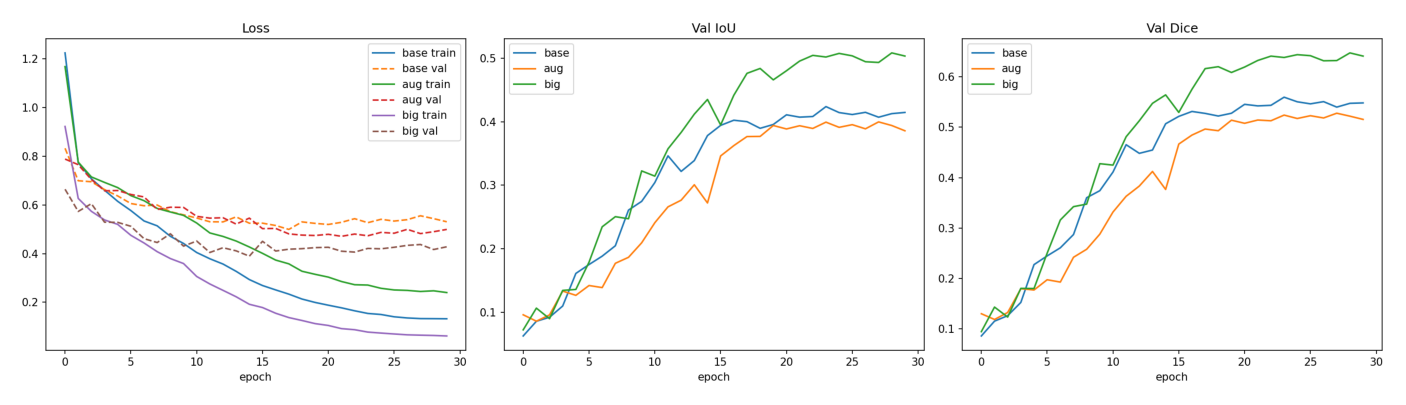

In [ ]:
img = Image.open('comparison.png')
plt.figure(figsize=(18, 5))
plt.imshow(img)
plt.axis('off')
plt.show()

**Выводы по графикам:**

Базовая модель:

Самая быстрая сходимость в начале, однако после 13-й эпохи val loss перестает падать и начинает немного расти. К 30-й эпохе образуется огромный разрыв между train и val (сильное переобучение). Кривые метрик выходят на плато примерно к 20-й эпохе. Модель показывает средний результат (IoU ~0.40, Dice ~0.53) и дальше практически не улучшается.


Модель с аугментациями:

Самая медленная сходимость на train. Зато val loss ведет себя наиболее стабильно: он плавно снижается до самого конца, без резкого роста. Разрыв между train и val минимальный среди всех моделей. Из-за медленного старта модель проигрывает базовой почти весь график метрик, но к концу (после 25-й эпохи) догоняет её (IoU ~0.40, Dice ~0.52).


Модель с увеличенным размером:

Самая низкая ошибка на train среди всех. val loss также снижается плавно и опускается ниже, чем у остальных моделей (до ~0.40), хотя разрыв с train остается значительным. Кривые метрик идут значительно выше остальных и демонстрируют уверенный рост без явного выхода на плато к 30-й эпохе. Модель достигает наилучших показателей (IoU ~0.50, Dice ~0.64), что подтверждает эффективность увеличения разрешения.

## Результаты

Saved: preds_base.png


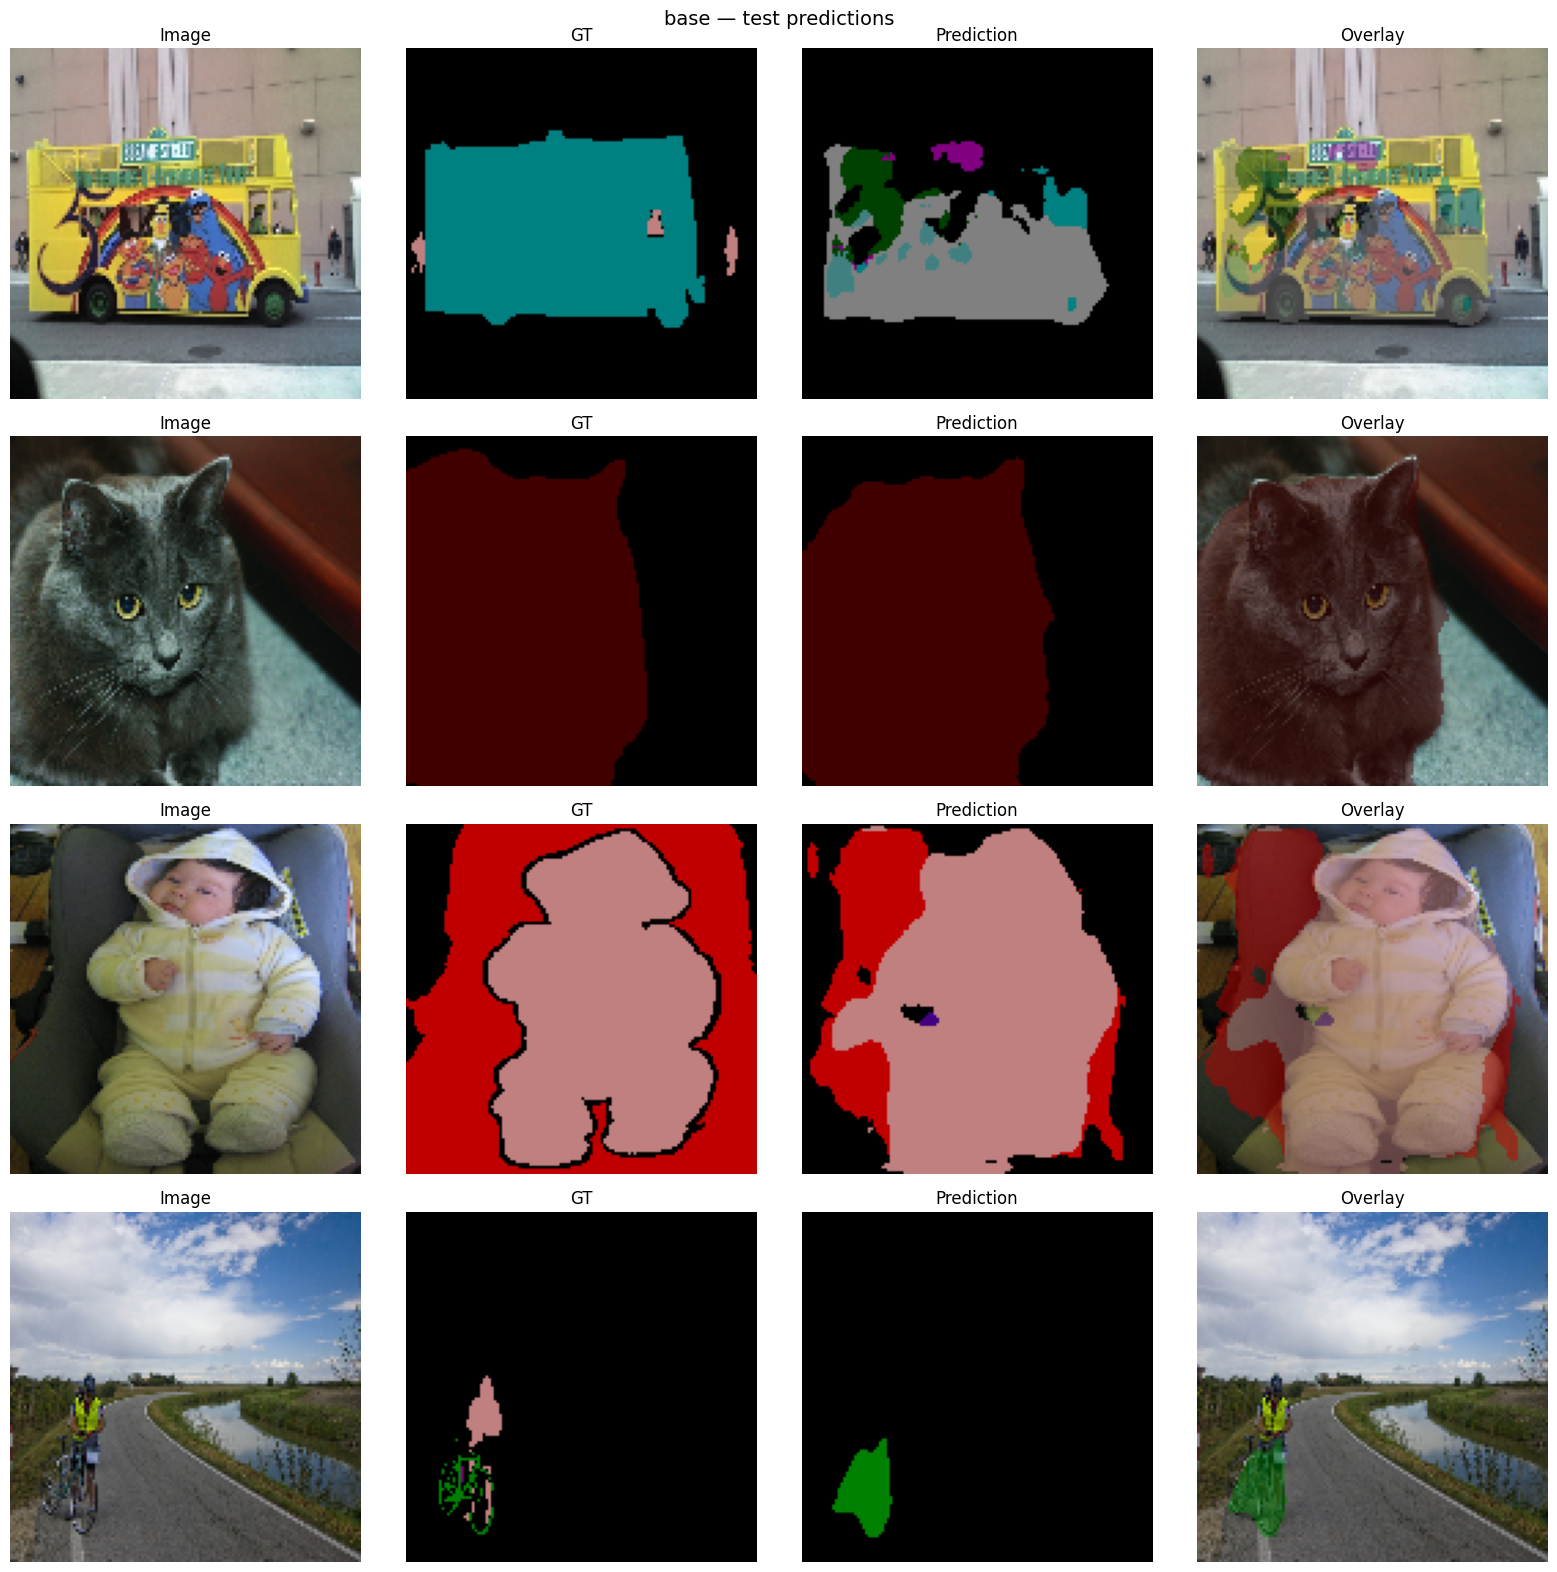

Saved: preds_aug.png


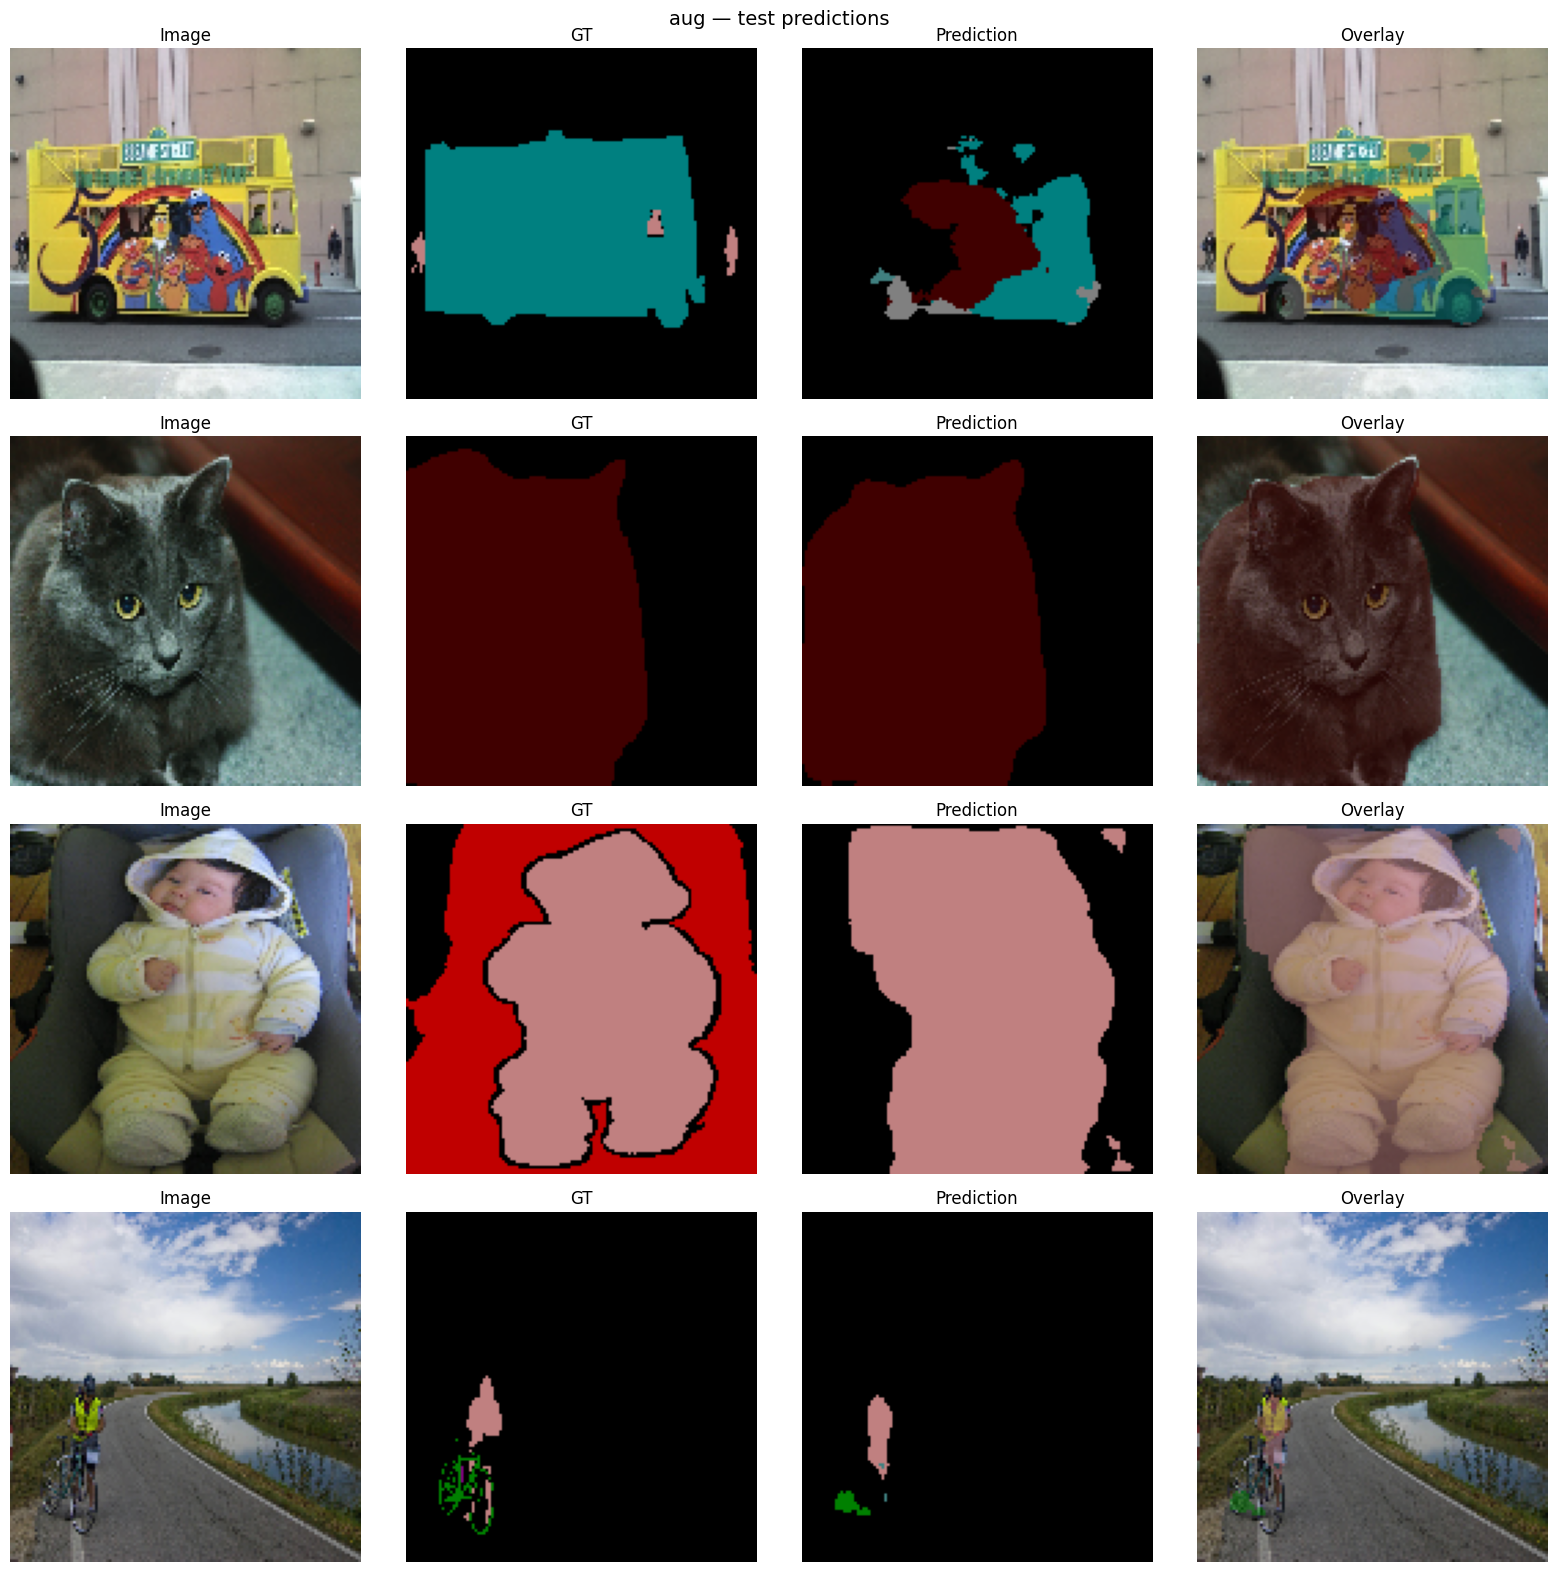

Saved: preds_big.png


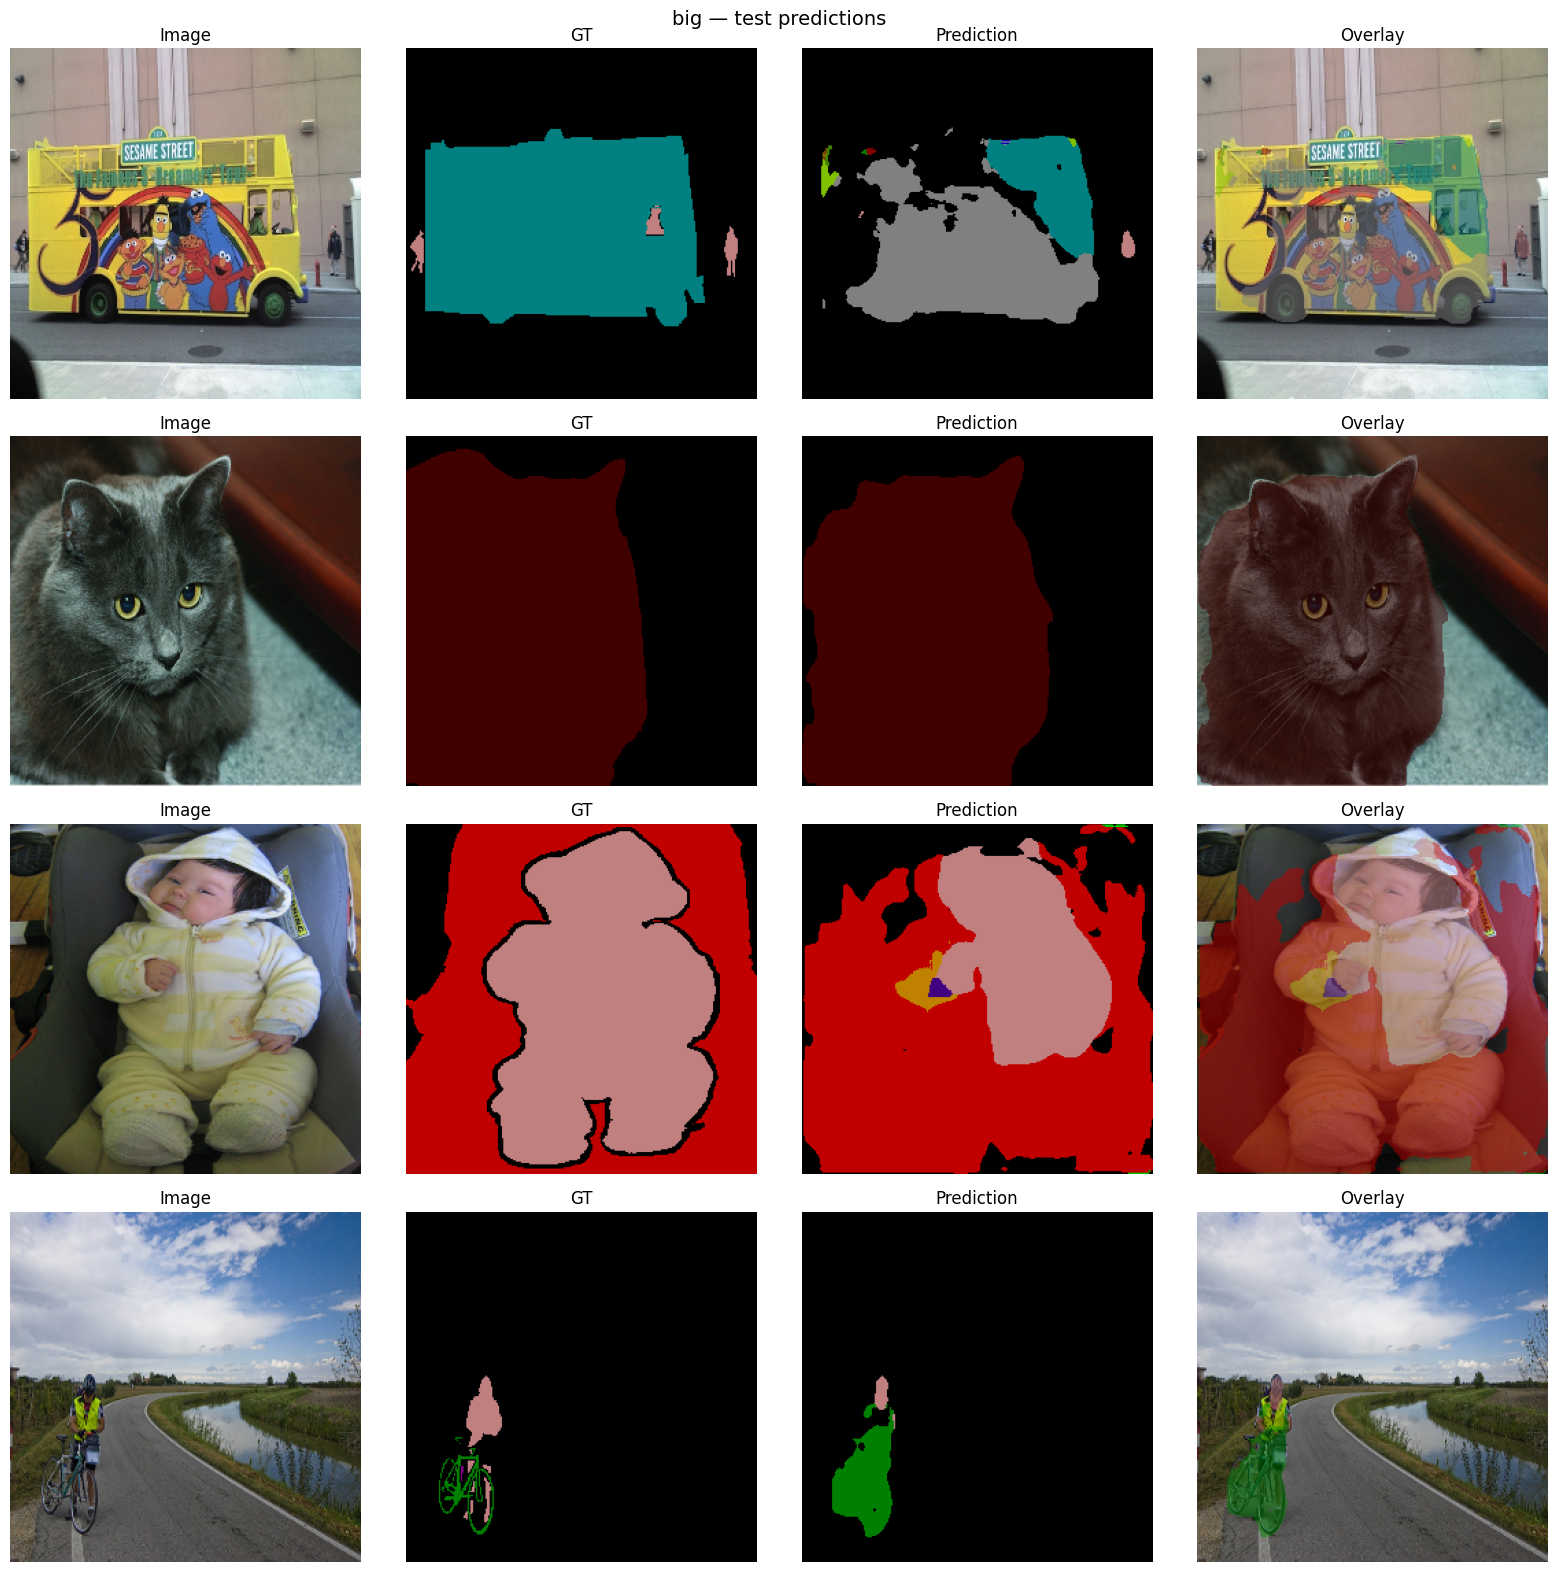

In [ ]:
for name, exp in experiments.items():
    visualize_predictions(
        exp['model'], exp['test_loader'],
        save_path=f'preds_{name}.png',
        n=4, title=f'{name} — test predictions',
    )

**Выводы:**

1. Базовая модель

Модель плохо справляется со сложными объектами. На примере с автобусом она выдает «кашу» из разных классов (серый, зеленый, фиолетовый) вместо цельного кузова.

В примере с велосипедистом модель не распознала человека, выделив лишь зеленое пятно, велосипед.

Однако крупные объекты с четкими границами (как кот) сегментируются достаточно уверенно, хотя края получаются немного рваными.

2. Модель с аугментациями

На примере с ребенком в кресле видно, что модель сильно переоценила площадь объекта (розовый цвет залез на красное кресло и фон).

Автобус предсказан как темно-красное пятно с кусками бирюзового, что свидетельствует о путанице классов.

Как и базовая модель, велосипедиста она распознает очень плохо (тонкая розовая полоска и крошечное зеленое пятно).

3.Модель с увеличенным разрешением

Визуально эта модель показывает самые аккуратные и гладкие контуры (особенно заметно на коте и ребенке).

На примере велосипедиста видно, что модель смогла отделить человека (розовый) от велосипеда (зеленый), пусть и не идеально.

Однако наблюдаются проблемы со сложными текстурами. Автобус все еще дается тяжело (путаница с цветами и классами машин/поездов), но общая форма объекта угадывается лучше, чем у базовой модели.



In [ ]:
cleanup_experiments(experiments, delete_models_only=True)

GPU memory allocated: 808.8 MB


## Контрольные вопросы

*Почему accuracy плохо отражает качество сегментации?*

Главная причина — сильный дисбаланс классов. В реальных изображениях фон может занимать 80–95% пикселей, а целевые объекты — лишь малую часть. Таким образом, если модель скажет, что все изображение - это только фон, то accuracy = пикселей_фона%. То есть accuracy высокая, однако модель бесполезна, так как не распознала мелкие детали, которые являлись целевыми объектами.

Поэтому в сегментации используют метрики, основанные на пересечении множеств — IoU и Dice. Они оценивают совпадение предсказанной маски с истинной отдельно по каждому классу, штрафуя модель за пропуски объектов и за захват лишних пикселей.

*Чем UNet отличается от "обычной" CNN?*

Обычные CNN предназначены для классификации — они выдают один ответ на всё изображение.

U-Net — это полносверточная сеть для семантической сегментации, она выдает маску, т.е. класс для каждого пикселя.

Главные отличия:

1. Архитектура Encoder-Decoder:
- Encoder: как в обычной CNN, уменьшает размер изображения и извлекает признаки.

- Decoder: восстанавливает пространственное разрешение обратно до исходного размера, чтобы получить попиксельную маску.

2. Сеть передает карты признаков с высоким разрешением напрямую из энкодера в декодер. Это позволяет точно восстанавливать мелкие детали и четкие границы объектов, когда в обычных CNN, где при сжатии теряется пространственная информация.

3. Обычная CNN выдает вектор вероятностей (размер N_classes), а U-Net — трехмерный тензор [N_classes, H, W].